Notebook 5 — Transformer Models

Install libraries

In [5]:
%pip install -U transformers datasets accelerate scikit-learn pandas numpy matplotlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 9.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 104.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 42.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 93.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.0/11.0 MB 97.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 81.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 102.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.1/50.1 MB 12.4 MB/s eta 0:00:00
  Attempting uninstall: pyarrow
    Found existing installation: pyarrow 18.1.0
    Uninstalling pyarrow-18.1.0:
      Successfully uninstalled pyarrow-18.1.0
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully un

**Imports and reproducibility**

In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/NLP"
)

In [1]:
from pathlib import Path
from collections import Counter
import gc
import json
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from datasets import Dataset, DatasetDict

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


Paths and processed data

Define project paths

In [2]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/NLP_Project"
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


output folders:

In [6]:
PROCESSED_DIR = PROJECT_ROOT / "processed_data"

MODEL_OUTPUT_DIR = (
    PROJECT_ROOT
    / "models"
    / "transformer_models"
)

RESULTS_DIR = PROJECT_ROOT / "results"
TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"
PREDICTIONS_DIR = RESULTS_DIR / "predictions"

for directory in [
    MODEL_OUTPUT_DIR,
    TABLES_DIR,
    FIGURES_DIR,
    PREDICTIONS_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Project root:", PROJECT_ROOT)
print("Processed data:", PROCESSED_DIR)

Project root: /content/drive/MyDrive/NLP_Project
Processed data: /content/drive/MyDrive/NLP_Project/processed_data


**Find the processed files safely**

---


This version also searches nearby folders if the fixed path is incorrect.

In [8]:
required_files = {
    "train": "train_utterances.csv",
    "validation": "validation_utterances.csv",
    "test": "test_utterances.csv"
}

candidate_roots = [
    PROCESSED_DIR,
    PROJECT_ROOT,
    PROJECT_ROOT.parent,
    Path("/content/") # Add /content/ to search for files directly in the Colab runtime
]

found_files = {}

for split_name, filename in required_files.items():
    matches = []

    for root in candidate_roots:
        if root.exists():
            matches.extend(
                root.rglob(filename)
            )

    # Remove duplicate paths.
    matches = list(
        dict.fromkeys(matches)
    )

    if not matches:
        raise FileNotFoundError(
            f"Could not find {filename}. "
            f"Searched from {candidate_roots}"
        )

    found_files[split_name] = matches[0]


TRAIN_PATH = found_files["train"]
VALIDATION_PATH = found_files["validation"]
TEST_PATH = found_files["test"]

print("Train:", TRAIN_PATH)
print("Validation:", VALIDATION_PATH)
print("Test:", TEST_PATH)


Train: /content/train_utterances.csv
Validation: /content/validation_utterances.csv
Test: /content/test_utterances.csv


In [9]:
train_df = pd.read_csv(TRAIN_PATH)
validation_df = pd.read_csv(
    VALIDATION_PATH
)
test_df = pd.read_csv(TEST_PATH)

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Train: (87170, 21)
Validation: (8069, 21)
Test: (7740, 21)


Validate required columns

In [10]:
REQUIRED_COLUMNS = {
    "dialogue_id",
    "turn_index",
    "utterance",
    "previous_3",
    "emotion_label",
    "emotion_name",
    "text_no_context",
    "text_context_1",
    "text_context_3",
    "text_full_context",
    "text_shuffled_context",
    "text_unrelated_context"
}

for split_name, dataframe in {
    "train": train_df,
    "validation": validation_df,
    "test": test_df
}.items():

    missing_columns = (
        REQUIRED_COLUMNS
        - set(dataframe.columns)
    )

    if missing_columns:
        raise ValueError(
            f"{split_name} is missing: "
            f"{sorted(missing_columns)}"
        )

    if dataframe[
        "emotion_label"
    ].isna().any():
        raise ValueError(
            f"{split_name} contains missing labels."
        )

print("All datasets passed validation.")

All datasets passed validation.


Labels and transformer experiments

Label configuration

In [11]:
LABEL_IDS = [0, 1, 2, 3, 4, 5, 6]

LABEL_NAMES = [
    "neutral",
    "anger",
    "disgust",
    "fear",
    "happiness",
    "sadness",
    "surprise"
]

ID_TO_LABEL = {
    label_id: label_name
    for label_id, label_name
    in zip(LABEL_IDS, LABEL_NAMES)
}

LABEL_TO_ID = {
    label_name: label_id
    for label_id, label_name
    in ID_TO_LABEL.items()
}

NUM_LABELS = len(LABEL_IDS)

**Defining all context experiments**

In [12]:
TRANSFORMER_EXPERIMENTS = {
    "no_context": "text_no_context",
    "previous_1": "text_context_1",
    "previous_3": "text_context_3",
    "full_context": "text_full_context",
    "shuffled_context": "text_shuffled_context",
    "unrelated_context": "text_unrelated_context"
}

for experiment, column in (
    TRANSFORMER_EXPERIMENTS.items()
):
    print(
        f"{experiment:20s} → {column}"
    )

no_context           → text_no_context
previous_1           → text_context_1
previous_3           → text_context_3
full_context         → text_full_context
shuffled_context     → text_shuffled_context
unrelated_context    → text_unrelated_context


**Tokenizer and special tokens**

Loading tokenizer


In [13]:
MODEL_NAME = "distilroberta-base"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

# Current utterance is placed at the end.
# Remove old context from the left when input is too long.
tokenizer.truncation_side = "left"

SPECIAL_TOKENS = {
    "additional_special_tokens": [
        "[SPEAKER_A]",
        "[SPEAKER_B]",
        "[TURN]",
        "[CURRENT]"
    ]
}

number_of_added_tokens = (
    tokenizer.add_special_tokens(
        SPECIAL_TOKENS
    )
)

print(
    "Added special tokens:",
    number_of_added_tokens
)

print(
    "Truncation side:",
    tokenizer.truncation_side
)

config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Added special tokens: 4
Truncation side: left


Preparing "Hugging Face datasets"

Dataframe preparation function

In [14]:
def prepare_huggingface_dataframe(
    dataframe,
    text_column
):
    if text_column not in dataframe.columns:
        raise KeyError(
            f"Missing column: {text_column}"
        )

    prepared = dataframe[
        [
            text_column,
            "emotion_label"
        ]
    ].copy()

    prepared = prepared.rename(
        columns={
            text_column: "text",
            "emotion_label": "labels"
        }
    )

    prepared["text"] = (
        prepared["text"]
        .fillna("")
        .astype(str)
    )

    prepared["labels"] = (
        prepared["labels"]
        .astype(int)
    )

    return prepared

**Creating train and validation only**

The test set is deliberately excluded during model development.

In [15]:
def create_development_dataset(
    text_column
):
    train_part = (
        prepare_huggingface_dataframe(
            train_df,
            text_column
        )
    )

    validation_part = (
        prepare_huggingface_dataframe(
            validation_df,
            text_column
        )
    )

    dataset = DatasetDict({
        "train": Dataset.from_pandas(
            train_part,
            preserve_index=False
        ),

        "validation":
            Dataset.from_pandas(
                validation_part,
                preserve_index=False
            )
    })

    return dataset

**Evaluating metrics**


Metrics function

In [16]:
def compute_metrics(
    evaluation_prediction
):
    logits, labels = evaluation_prediction

    predictions = np.argmax(
        logits,
        axis=-1
    )

    emotional_mask = labels != 0

    results = {
        "accuracy": accuracy_score(
            labels,
            predictions
        ),

        "balanced_accuracy":
            balanced_accuracy_score(
                labels,
                predictions
            ),

        "macro_f1": f1_score(
            labels,
            predictions,
            labels=LABEL_IDS,
            average="macro",
            zero_division=0
        ),

        "weighted_f1": f1_score(
            labels,
            predictions,
            labels=LABEL_IDS,
            average="weighted",
            zero_division=0
        )
    }

    if emotional_mask.any():
        results[
            "accuracy_on_true_emotional_examples"
        ] = accuracy_score(
            labels[emotional_mask],
            predictions[emotional_mask]
        )

    return results

**Moderate class weighting**

using square-root balanced weights.

Calculate moderate weights

In [17]:
y_train = (
    train_df["emotion_label"]
    .astype(int)
    .to_numpy()
)

class_counts = Counter(y_train)

total_training_examples = len(y_train)
number_of_classes = NUM_LABELS

fully_balanced_weights = {
    label: (
        total_training_examples
        / (
            number_of_classes
            * class_counts[label]
        )
    )
    for label in LABEL_IDS
}

sqrt_balanced_weights = {
    label: float(
        np.sqrt(weight)
    )
    for label, weight
    in fully_balanced_weights.items()
}

class_weights_tensor = torch.tensor(
    [
        sqrt_balanced_weights[
            label
        ]
        for label in LABEL_IDS
    ],
    dtype=torch.float32
)

print("Training class counts:")
print(class_counts)

print("\nSquare-root weights:")
print(class_weights_tensor)

assert len(
    class_weights_tensor
) == NUM_LABELS

assert torch.isfinite(
    class_weights_tensor
).all()

Training class counts:
Counter({np.int64(0): 72143, np.int64(4): 11182, np.int64(6): 1600, np.int64(5): 969, np.int64(1): 827, np.int64(2): 303, np.int64(3): 146})

Square-root weights:
tensor([0.4155, 3.8804, 6.4108, 9.2355, 1.0553, 3.5849, 2.7898])


**Custom weighted Trainer**

Weighted loss

In [18]:
class WeightedTrainer(Trainer):
    def __init__(
        self,
        *args,
        class_weights=None,
        **kwargs
    ):
        if class_weights is None:
            raise ValueError(
                "class_weights must be provided."
            )

        self.class_weights = (
            class_weights
            .detach()
            .clone()
            .float()
        )

        super().__init__(
            *args,
            **kwargs
        )

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        model_inputs = inputs.copy()

        labels = model_inputs.pop(
            "labels"
        )

        outputs = model(
            **model_inputs
        )

        logits = outputs.logits

        weights = self.class_weights.to(
            device=logits.device,
            dtype=logits.dtype
        )

        loss_function = (
            torch.nn.CrossEntropyLoss(
                weight=weights
            )
        )

        loss = loss_function(
            logits.view(
                -1,
                model.config.num_labels
            ),
            labels.view(-1)
        )

        if return_outputs:
            return loss, outputs

        return loss

**Complete training function**


Train one transformer experiment

In [19]:
def run_transformer_experiment(
    experiment_name,
    text_column,
    max_length=256,
    number_of_epochs=5
):
    print("\n" + "=" * 80)
    print(
        f"EXPERIMENT: {experiment_name}"
    )
    print(
        f"TEXT COLUMN: {text_column}"
    )
    print("=" * 80)

    # ------------------------------------------
    # 1. Create train and validation datasets
    # ------------------------------------------
    dataset = (
        create_development_dataset(
            text_column
        )
    )

    def tokenize_batch(batch):
        return tokenizer(
            batch["text"],
            truncation=True,
            max_length=max_length
        )

    tokenized_dataset = dataset.map(
        tokenize_batch,
        batched=True,
        remove_columns=["text"]
    )

    print(tokenized_dataset)

    # Confirm full training split is used.
    if (
        len(tokenized_dataset["train"])
        != len(train_df)
    ):
        raise ValueError(
            "Tokenized training set does not "
            "contain the full training split."
        )

    # ------------------------------------------
    # 2. Create a fresh model
    # ------------------------------------------
    model = (
        AutoModelForSequenceClassification
        .from_pretrained(
            MODEL_NAME,
            num_labels=NUM_LABELS,
            id2label=ID_TO_LABEL,
            label2id=LABEL_TO_ID
        )
    )

    model.resize_token_embeddings(
        len(tokenizer)
    )

    model.config.use_cache = False

    experiment_directory = (
        MODEL_OUTPUT_DIR
        / f"distilroberta_{experiment_name}"
    )

    experiment_directory.mkdir(
        parents=True,
        exist_ok=True
    )

    # ------------------------------------------
    # 3. Training arguments
    # ------------------------------------------
    training_arguments = TrainingArguments(
        output_dir=str(
            experiment_directory
        ),

        learning_rate=2e-5,
        weight_decay=0.01,

        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,

        gradient_accumulation_steps=1,

        num_train_epochs=
            number_of_epochs,

        warmup_steps=500,

        eval_strategy="epoch",
        save_strategy="epoch",

        logging_strategy="steps",
        logging_steps=200,

        load_best_model_at_end=True,

        metric_for_best_model=
            "macro_f1",

        greater_is_better=True,

        save_total_limit=2,

        fp16=(
            torch.cuda.is_available()
        ),

        bf16=False,

        seed=SEED,
        data_seed=SEED,

        report_to="none"
    )

    data_collator = (
        DataCollatorWithPadding(
            tokenizer=tokenizer
        )
    )

    # ------------------------------------------
    # 4. Trainer
    # ------------------------------------------
    trainer = WeightedTrainer(
        model=model,
        args=training_arguments,

        train_dataset=
            tokenized_dataset["train"],

        eval_dataset=
            tokenized_dataset[
                "validation"
            ],

        processing_class=tokenizer,

        data_collator=
            data_collator,

        compute_metrics=
            compute_metrics,

        callbacks=[
            EarlyStoppingCallback(
                early_stopping_patience=2
            )
        ],

        class_weights=
            class_weights_tensor
    )

    # ------------------------------------------
    # 5. Train
    # ------------------------------------------
    training_output = trainer.train()

    print("\nTraining completed.")
    print(training_output)

    # ------------------------------------------
    # 6. Validation evaluation
    # ------------------------------------------
    validation_output = trainer.predict(
        tokenized_dataset[
            "validation"
        ]
    )

    validation_predictions = np.argmax(
        validation_output.predictions,
        axis=-1
    )

    validation_labels = (
        validation_df[
            "emotion_label"
        ]
        .astype(int)
        .to_numpy()
    )

    validation_metrics = (
        compute_metrics(
            (
                validation_output.predictions,
                validation_labels
            )
        )
    )

    validation_metrics.update({
        "experiment":
            experiment_name,

        "text_column":
            text_column,

        "max_length":
            max_length,

        "epochs_completed":
            float(
                training_output.metrics.get(
                    "epoch",
                    np.nan
                )
            ),

        "validation_loss":
            float(
                validation_output.metrics[
                    "test_loss"
                ]
            )
    })

    print("\nValidation metrics:")
    print(
        pd.Series(
            validation_metrics
        )
    )

    # ------------------------------------------
    # 7. Classification report
    # ------------------------------------------
    report = classification_report(
        validation_labels,
        validation_predictions,
        labels=LABEL_IDS,
        target_names=LABEL_NAMES,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(
        report
    ).transpose()

    display(
        report_df.round(4)
    )

    report_df.to_csv(
        TABLES_DIR
        / (
            f"transformer_"
            f"{experiment_name}_"
            f"validation_report.csv"
        )
    )

    # ------------------------------------------
    # 8. Save predictions
    # ------------------------------------------
    prediction_df = validation_df[
        [
            "dialogue_id",
            "turn_index",
            "utterance",
            "previous_3",
            "emotion_label",
            "emotion_name"
        ]
    ].copy()

    prediction_df[
        "predicted_label"
    ] = validation_predictions

    prediction_df[
        "predicted_emotion"
    ] = (
        prediction_df[
            "predicted_label"
        ].map(ID_TO_LABEL)
    )

    prediction_df[
        "correct"
    ] = (
        prediction_df[
            "emotion_label"
        ]
        == prediction_df[
            "predicted_label"
        ]
    )

    prediction_df[
        "experiment"
    ] = experiment_name

    prediction_df.to_csv(
        PREDICTIONS_DIR
        / (
            f"transformer_"
            f"{experiment_name}_"
            f"validation_predictions.csv"
        ),
        index=False
    )

    # ------------------------------------------
    # 9. Save best model
    # ------------------------------------------
    best_model_directory = (
        experiment_directory
        / "best_model"
    )

    trainer.save_model(
        str(best_model_directory)
    )

    tokenizer.save_pretrained(
        str(best_model_directory)
    )

    # ------------------------------------------
    # 10. Clean memory
    # ------------------------------------------
    del trainer
    del model
    del tokenized_dataset
    del dataset

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return validation_metrics

**Running all validation experiments**


Results file and experiment loop

This codeblock saves the results after every experiment, including previous_1 and full_context.

In [21]:
RESULTS_FILE = (
    TABLES_DIR
    / "transformer_validation_results.csv"
)

transformer_results = []

for experiment_name, text_column in (
    TRANSFORMER_EXPERIMENTS.items()
):
    metrics = (
        run_transformer_experiment(
            experiment_name=
                experiment_name,

            text_column=
                text_column,

            max_length=256,

            number_of_epochs=5
        )
    )

    transformer_results.append(
        metrics
    )

    # Save immediately after every run.
    pd.DataFrame(
        transformer_results
    ).to_csv(
        RESULTS_FILE,
        index=False
    )

print(
    "All validation experiments completed."
)


EXPERIMENT: no_context
TEXT COLUMN: text_no_context


Map:   0%|          | 0/87170 [00:00<?, ? examples/s]

Map:   0%|          | 0/8069 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 87170
    })
    validation: Dataset({
        features: ['labels', 'input_ids', 'attention_mask'],
        num_rows: 8069
    })
})


Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: distilroberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (87 outputs left out)


Validation metrics:
accuracy                                             0.875945
balanced_accuracy                                    0.515905
macro_f1                                             0.456455
weighted_f1                                          0.886474
accuracy_on_true_emotional_examples                  0.710718
experiment                                  unrelated_context
text_column                            text_unrelated_context
max_length                                                256
epochs_completed                                          5.0
validation_loss                                      0.707518
dtype: object


,precision,recall,f1-score,support
neutral,0.9651,0.8983,0.9305,7108.0000
anger,0.5323,0.4286,0.4748,77.0000
disgust,0.0833,0.3333,0.1333,3.0000
fear,0.2857,0.1818,0.2222,11.0000
happiness,0.4955,0.8129,0.6157,684.0000
sadness,0.2712,0.4051,0.3249,79.0000
surprise,0.4470,0.5514,0.4937,107.0000
accuracy,0.8759,0.8759,0.8759,0.8759
macro avg,0.4400,0.5159,0.4565,8069.0000
weighted avg,0.9062,0.8759,0.8865,8069.0000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

All validation experiments completed.


**Comparing all validation results**

Load and rank every experiment

In [22]:
transformer_results_df = pd.read_csv(
    RESULTS_FILE
)

required_experiments = set(
    TRANSFORMER_EXPERIMENTS.keys()
)

completed_experiments = set(
    transformer_results_df[
        "experiment"
    ]
)

missing_experiments = (
    required_experiments
    - completed_experiments
)

if missing_experiments:
    print(
        "Experiments still missing:",
        sorted(missing_experiments)
    )

transformer_results_df = (
    transformer_results_df
    .sort_values(
        "macro_f1",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    transformer_results_df[
        [
            "experiment",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "weighted_f1",
            "accuracy_on_true_emotional_examples"
        ]
    ].round(4)
)

,experiment,accuracy,balanced_accuracy,macro_f1,weighted_f1,accuracy_on_true_emotional_examples
0,full_context,0.8957,0.4903,0.4722,0.9020,0.7014
1,shuffled_context,0.8851,0.5276,0.4675,0.8948,0.7097
2,previous_1,0.8829,0.4906,0.4578,0.8927,0.7222
3,unrelated_context,0.8759,0.5159,0.4565,0.8865,0.7107
4,previous_3,0.8892,0.4925,0.4544,0.8976,0.7170
5,no_context,0.8740,0.5090,0.4533,0.8866,0.7388


Ploting validation Macro-F1

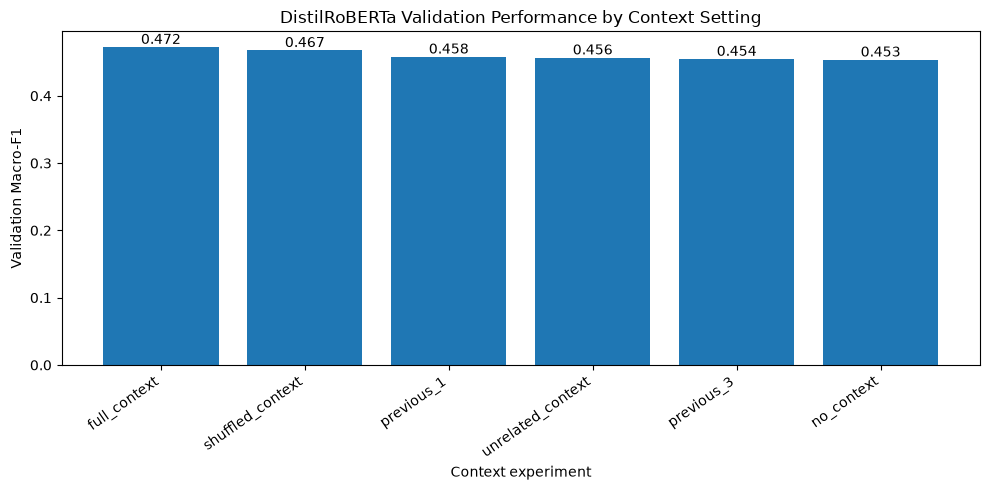

In [23]:
plt.figure(figsize=(10, 5))

positions = np.arange(
    len(transformer_results_df)
)

plt.bar(
    positions,
    transformer_results_df[
        "macro_f1"
    ]
)

plt.xticks(
    positions,
    transformer_results_df[
        "experiment"
    ],
    rotation=35,
    ha="right"
)

plt.ylabel("Validation Macro-F1")
plt.xlabel("Context experiment")

plt.title(
    "DistilRoBERTa Validation Performance "
    "by Context Setting"
)

for index, value in enumerate(
    transformer_results_df[
        "macro_f1"
    ]
):
    plt.text(
        index,
        value + 0.005,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / "transformer_validation_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Automatically select the real best model**


Validation-based selection

In [24]:
best_row = transformer_results_df.loc[
    transformer_results_df[
        "macro_f1"
    ].idxmax()
]

BEST_EXPERIMENT = best_row[
    "experiment"
]

BEST_TEXT_COLUMN = (
    TRANSFORMER_EXPERIMENTS[
        BEST_EXPERIMENT
    ]
)

BEST_VALIDATION_MACRO_F1 = float(
    best_row["macro_f1"]
)

print("BEST TRANSFORMER MODEL")
print("=" * 60)

print(
    "Experiment:",
    BEST_EXPERIMENT
)

print(
    "Text column:",
    BEST_TEXT_COLUMN
)

print(
    "Validation accuracy:",
    f"{best_row['accuracy']:.4f}"
)

print(
    "Validation Macro-F1:",
    f"{best_row['macro_f1']:.4f}"
)

print(
    "Validation weighted-F1:",
    f"{best_row['weighted_f1']:.4f}"
)

BEST TRANSFORMER MODEL
Experiment: full_context
Text column: text_full_context
Validation accuracy: 0.8957
Validation Macro-F1: 0.4722
Validation weighted-F1: 0.9020


**Final test evaluation**

Only after all validation experiments are finished.

Locate the selected model

In [25]:
BEST_MODEL_DIRECTORY = (
    MODEL_OUTPUT_DIR
    / f"distilroberta_{BEST_EXPERIMENT}"
    / "best_model"
)

if not BEST_MODEL_DIRECTORY.exists():
    raise FileNotFoundError(
        f"Model not found: "
        f"{BEST_MODEL_DIRECTORY}"
    )

print(
    "Loading:",
    BEST_MODEL_DIRECTORY
)

Loading: /content/drive/MyDrive/NLP_Project/models/transformer_models/distilroberta_full_context/best_model


Loading model and tokenizer

In [26]:
best_tokenizer = (
    AutoTokenizer.from_pretrained(
        BEST_MODEL_DIRECTORY
    )
)

best_tokenizer.truncation_side = "left"

best_model = (
    AutoModelForSequenceClassification
    .from_pretrained(
        BEST_MODEL_DIRECTORY
    )
)

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Preparing the test dataset

In [27]:
test_prepared_df = (
    prepare_huggingface_dataframe(
        test_df,
        BEST_TEXT_COLUMN
    )
)

test_dataset = Dataset.from_pandas(
    test_prepared_df,
    preserve_index=False
)


def tokenize_test_batch(batch):
    return best_tokenizer(
        batch["text"],
        truncation=True,
        max_length=256
    )


tokenized_test_dataset = (
    test_dataset.map(
        tokenize_test_batch,
        batched=True,
        remove_columns=["text"]
    )
)

Map:   0%|          | 0/7740 [00:00<?, ? examples/s]

**Predicting on the held-out test set**

In [28]:
test_trainer = Trainer(
    model=best_model,

    processing_class=
        best_tokenizer,

    data_collator=
        DataCollatorWithPadding(
            tokenizer=
                best_tokenizer
        ),

    compute_metrics=
        compute_metrics
)

test_output = test_trainer.predict(
    tokenized_test_dataset
)

test_predictions = np.argmax(
    test_output.predictions,
    axis=-1
)

y_test = (
    test_df["emotion_label"]
    .astype(int)
    .to_numpy()
)

final_test_metrics = compute_metrics(
    (
        test_output.predictions,
        y_test
    )
)

final_test_metrics.update({
    "model":
        "DistilRoBERTa",

    "selected_experiment":
        BEST_EXPERIMENT,

    "selected_text_column":
        BEST_TEXT_COLUMN,

    "validation_macro_f1":
        BEST_VALIDATION_MACRO_F1
})

print("FINAL TRANSFORMER TEST RESULTS")
print("=" * 60)

print(
    pd.Series(
        final_test_metrics
    )
)

FINAL TRANSFORMER TEST RESULTS
accuracy                                        0.847545
balanced_accuracy                               0.538069
macro_f1                                        0.538242
weighted_f1                                      0.85029
accuracy_on_true_emotional_examples             0.610994
model                                      DistilRoBERTa
selected_experiment                         full_context
selected_text_column                   text_full_context
validation_macro_f1                              0.47217
dtype: object


**Final classification report**

In [29]:
final_test_report = (
    classification_report(
        y_test,
        test_predictions,
        labels=LABEL_IDS,
        target_names=LABEL_NAMES,
        output_dict=True,
        zero_division=0
    )
)

final_test_report_df = pd.DataFrame(
    final_test_report
).transpose()

display(
    final_test_report_df.round(4)
)

pd.DataFrame(
    [final_test_metrics]
).to_csv(
    TABLES_DIR
    / "final_transformer_test_metrics.csv",
    index=False
)

final_test_report_df.to_csv(
    TABLES_DIR
    / (
        "final_transformer_"
        "test_classification_report.csv"
    )
)

,precision,recall,f1-score,support
neutral,0.9212,0.9006,0.9108,6321.0000
anger,0.4757,0.4153,0.4434,118.0000
disgust,0.4848,0.3404,0.4000,47.0000
fear,0.6364,0.4118,0.5000,17.0000
happiness,0.6064,0.6683,0.6359,1019.0000
sadness,0.3704,0.3922,0.3810,102.0000
surprise,0.4066,0.6379,0.4966,116.0000
accuracy,0.8475,0.8475,0.8475,0.8475
macro avg,0.5574,0.5381,0.5382,7740.0000
weighted avg,0.8547,0.8475,0.8503,7740.0000


Test confusion matrix

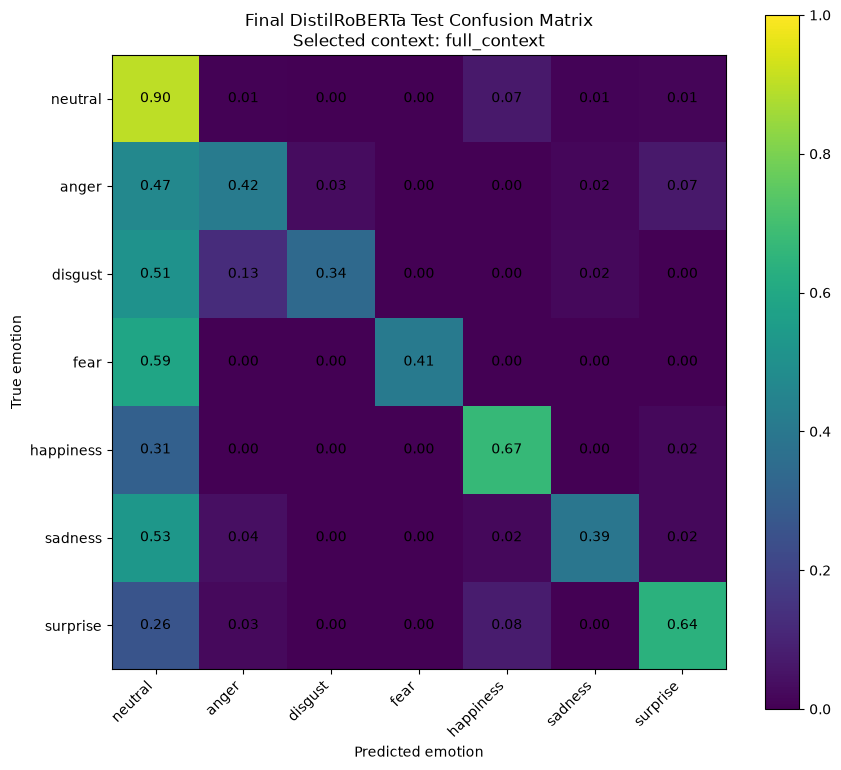

In [30]:
normalized_test_cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=LABEL_IDS,
    normalize="true"
)

fig, ax = plt.subplots(
    figsize=(9, 8)
)

image = ax.imshow(
    normalized_test_cm,
    vmin=0,
    vmax=1
)

ax.set_xticks(
    range(NUM_LABELS)
)

ax.set_xticklabels(
    LABEL_NAMES,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    range(NUM_LABELS)
)

ax.set_yticklabels(
    LABEL_NAMES
)

for row in range(NUM_LABELS):
    for column in range(NUM_LABELS):
        ax.text(
            column,
            row,
            f"{normalized_test_cm[row, column]:.2f}",
            ha="center",
            va="center"
        )

ax.set_title(
    "Final DistilRoBERTa Test "
    "Confusion Matrix\n"
    f"Selected context: {BEST_EXPERIMENT}"
)

ax.set_xlabel("Predicted emotion")
ax.set_ylabel("True emotion")

fig.colorbar(image)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR
    / (
        "final_transformer_"
        "test_confusion_matrix.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Save the final prediction**

In [31]:
final_prediction_df = test_df[
    [
        "dialogue_id",
        "turn_index",
        "previous_3",
        "utterance",
        "emotion_label",
        "emotion_name"
    ]
].copy()

final_prediction_df[
    "predicted_label"
] = test_predictions

final_prediction_df[
    "predicted_emotion"
] = (
    final_prediction_df[
        "predicted_label"
    ].map(ID_TO_LABEL)
)

final_prediction_df[
    "correct"
] = (
    final_prediction_df[
        "emotion_label"
    ]
    == final_prediction_df[
        "predicted_label"
    ]
)

final_prediction_df[
    "selected_experiment"
] = BEST_EXPERIMENT

final_prediction_df.to_csv(
    PREDICTIONS_DIR
    / "final_transformer_test_predictions.csv",
    index=False
)

print(
    "Final predictions saved successfully."
)

Final predictions saved successfully.


Qualitative error analysis

In [32]:
test_errors_df = (
    final_prediction_df.loc[
        ~final_prediction_df["correct"]
    ]
    .copy()
)

error_examples_df = test_errors_df.sample(
    n=min(
        20,
        len(test_errors_df)
    ),
    random_state=SEED
)

error_examples_df[
    "manual_comment"
] = ""

display(
    error_examples_df[
        [
            "previous_3",
            "utterance",
            "emotion_name",
            "predicted_emotion",
            "manual_comment"
        ]
    ]
)

error_examples_df.to_csv(
    TABLES_DIR
    / "transformer_test_error_examples.csv",
    index=False
)

,previous_3,utterance,emotion_name,predicted_emotion,manual_comment
1920,"[SPEAKER_B] yes . [SEP] [SPEAKER_A] well , the...",she said that the columnist for the literary c...,happiness,neutral,
628,[SPEAKER_A] Excuse me . I have an appointment ...,"Yes , I am My Liu . Thanks .",neutral,happiness,
6714,"[SPEAKER_A] No , but my little brother likes i...","Wow , that sounds like a scholar . By the way ...",neutral,happiness,
4981,[SPEAKER_B] Stop making fun of me . [SEP] [SPE...,"Oh , I see . You're going to wear one and pret...",happiness,neutral,
1975,[SPEAKER_A] Thank you so much . Does he read h...,My pleasure . I hope you get a hold of him .,neutral,happiness,
4274,"[SPEAKER_A] that was a really good meal , Gord...",It sure was . I couldn't eat another bite .,happiness,neutral,
5437,[SPEAKER_A] I thought it would have been more ...,Ok .,neutral,happiness,
7683,NaN,We are planning to go to Beidaihe for vacation...,happiness,neutral,
3693,"[SPEAKER_A] You have a lovely house , Jack . [...",That's too bad . What problems are you having .,sadness,neutral,
7169,[SPEAKER_A] Gross ! What are you doing to your...,You're such a wimp ! You're afraid of an eyela...,neutral,anger,


**Comparing Transformer with Sentence-BERT**

Model-family comparison

In [42]:
SBERT_RESULTS_PATH = (
    TABLES_DIR
    / "final_sbert_test_metrics.csv"
)

TRANSFORMER_RESULTS_PATH = (
    TABLES_DIR
    / "final_transformer_test_metrics.csv"
)

comparison_frames = []

if SBERT_RESULTS_PATH.exists():
    sbert_results = pd.read_csv(
        SBERT_RESULTS_PATH
    )

    sbert_results[
        "model_family"
    ] = "Sentence-BERT"

    comparison_frames.append(
        sbert_results
    )

transformer_results = pd.read_csv(
    TRANSFORMER_RESULTS_PATH
)
transformer_results[
    "model_family"
] = "Fine-tuned Transformer"

comparison_frames.append(
    transformer_results
)

final_model_comparison = pd.concat(
    comparison_frames,
    ignore_index=True,
    sort=False
)

display(
    final_model_comparison[
        [
            "model_family",
            "accuracy",
            "balanced_accuracy",
            "macro_f1",
            "weighted_f1"
        ]
    ].round(4)
)

final_model_comparison.to_csv(
    TABLES_DIR
    / "sbert_transformer_test_comparison.csv",
    index=False
)


,model_family,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,Sentence-BERT,0.8021,0.4808,0.4117,0.8131
1,Fine-tuned Transformer,0.8475,0.5381,0.5382,0.8503


### Short Discussion of Transformer Results

DistilRoBERTa was fine-tuned using six context settings, with **full context** achieving the best validation performance (**Accuracy = 0.8957, Macro-F1 = 0.4722, Weighted-F1 = 0.9020**). On the **held-out test set**, the selected model achieved **84.75% accuracy**, **53.81% balanced accuracy**, **53.82% Macro-F1**, and **85.03% Weighted-F1**, demonstrating good generalization to unseen conversations.

The model performed best on **neutral** and **happiness**, while **disgust** and **sadness** remained the most difficult classes due to severe class imbalance and limited training examples. Compared with the Sentence-BERT baseline, the fine-tuned transformer achieved higher performance across all evaluation metrics, showing that task-specific fine-tuning learns richer emotional and contextual representations for conversational emotion recognition.
